# Gateway: Lambda e servidor MCP

20 minutos • Referências G1, G2, G8

Referências: [catálogo e links fixados](../referencias-notebooks-agentcore.md).
Execute com o kernel Python de `.venv`.

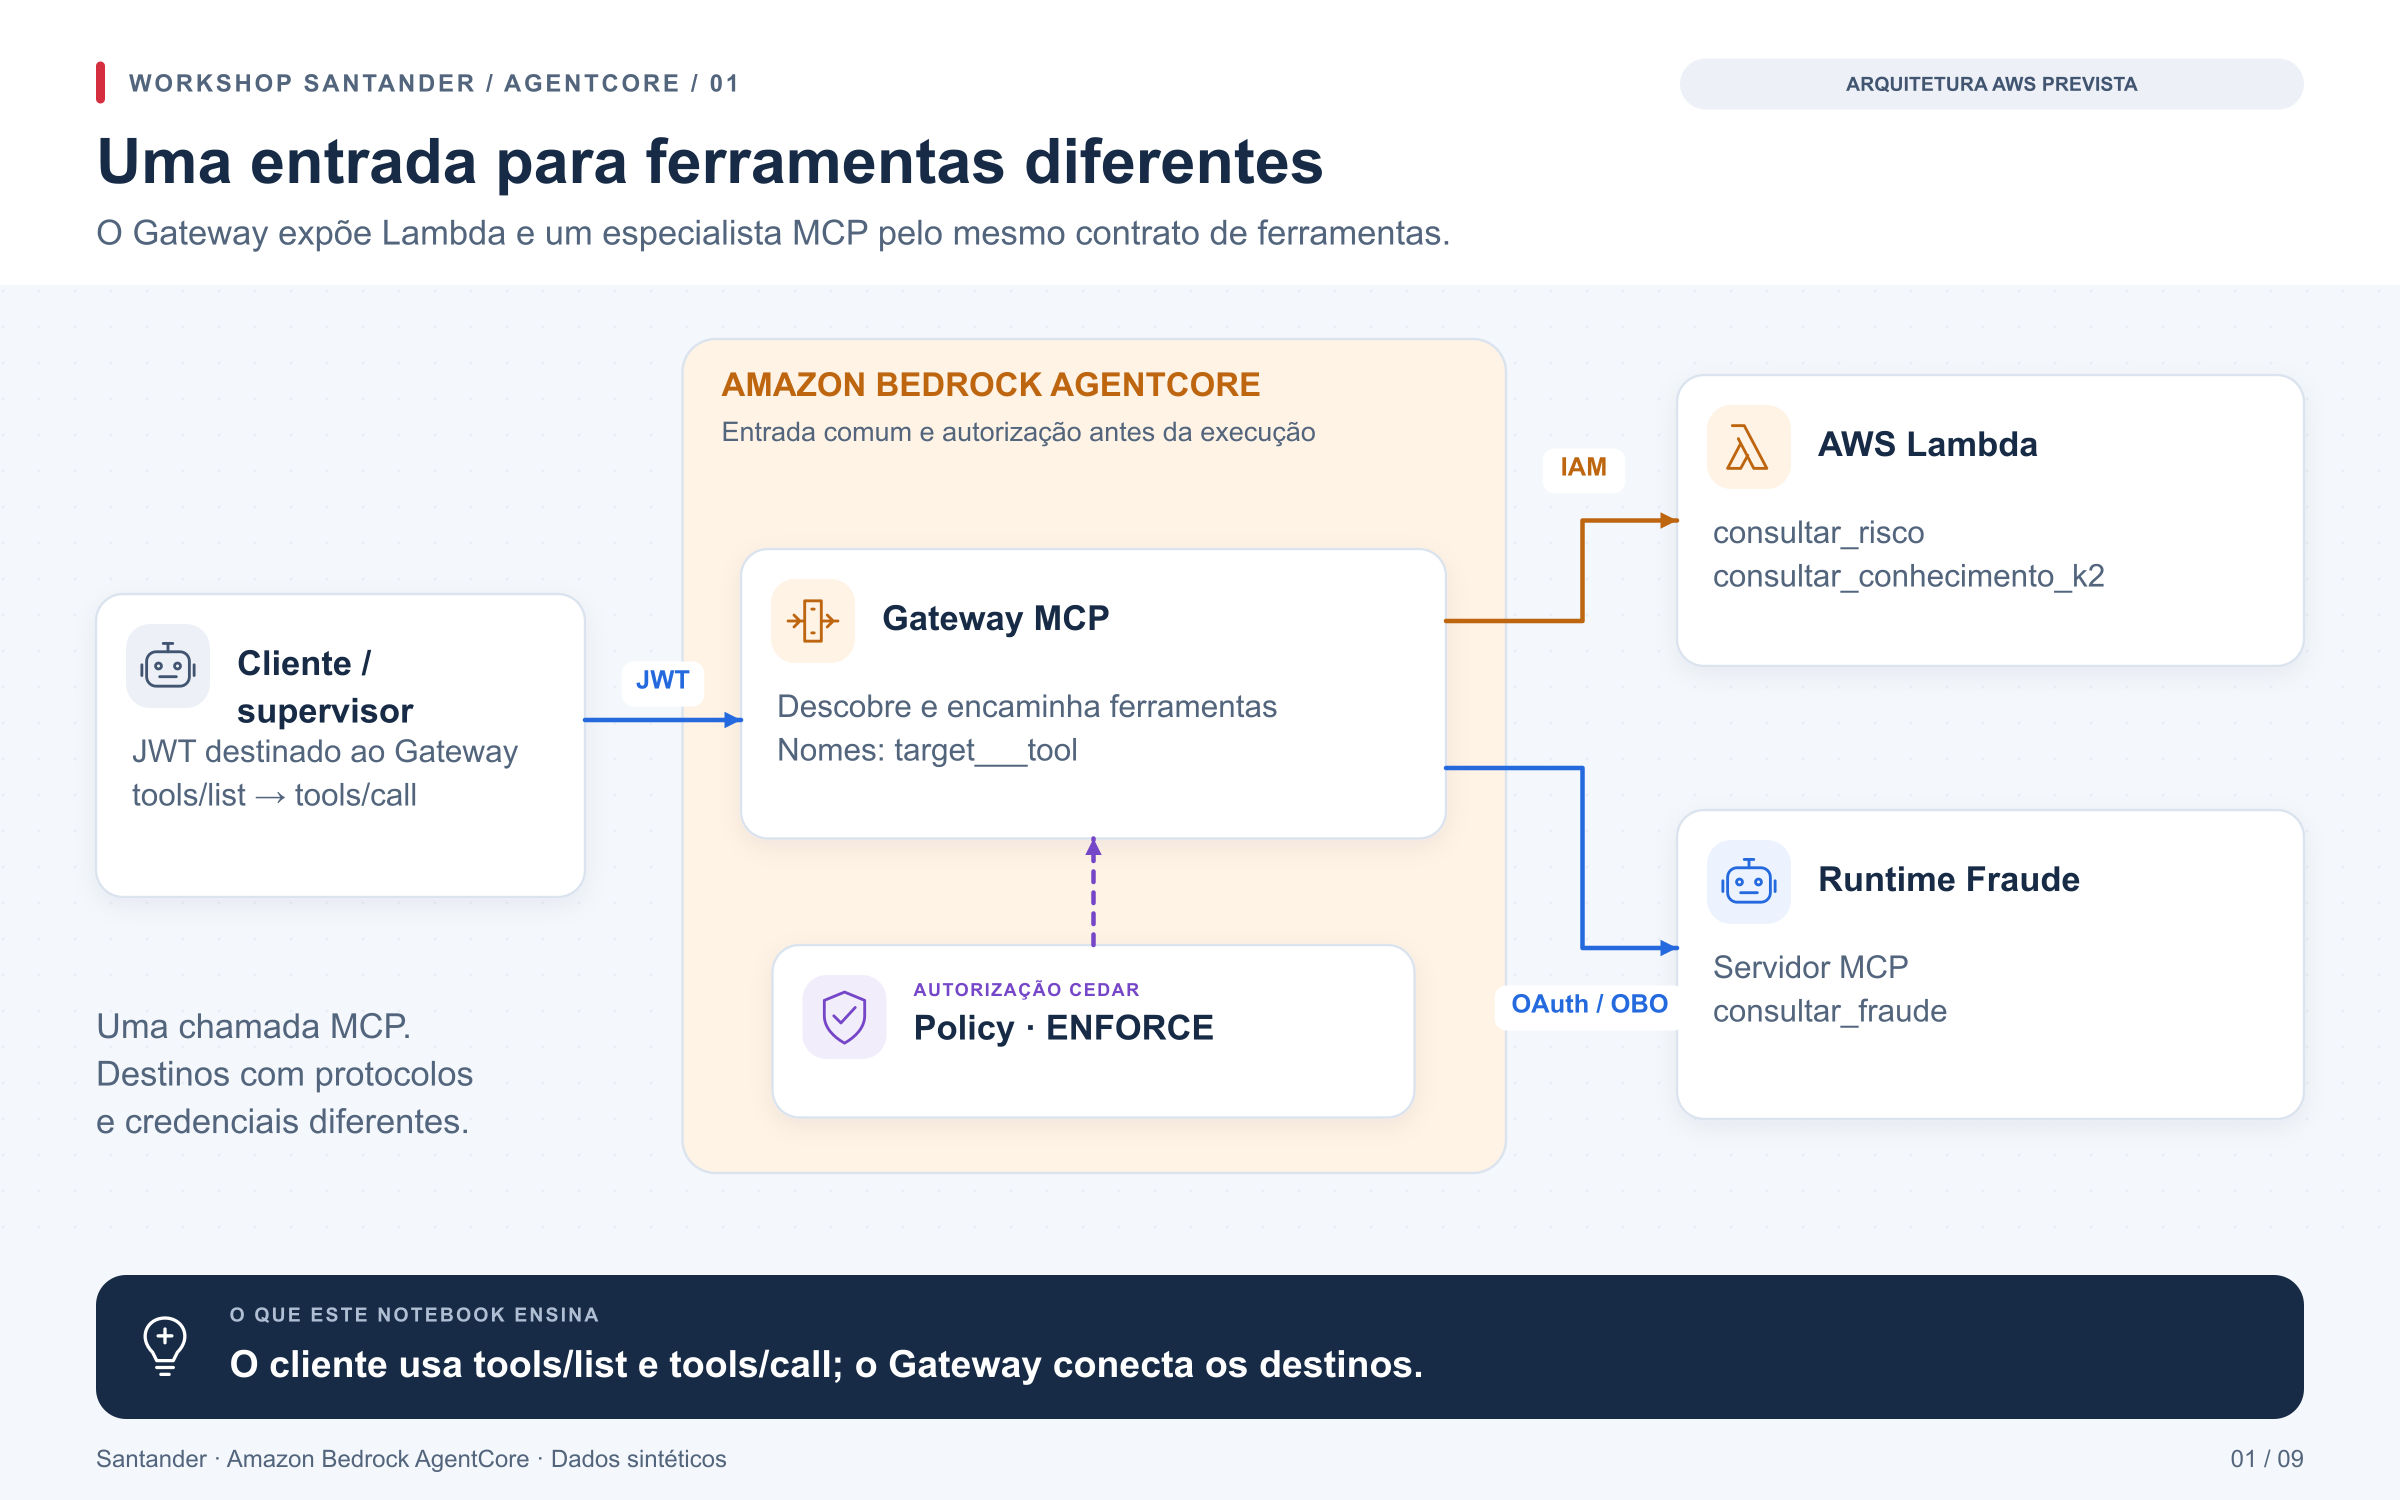

**Objetivo visual:** Encontrar os nomes reais das tools e executar uma chamada pelo caminho autorizado.

[Abrir PNG](../docs/diagramas/png/01_gateway_targets.png) · [SVG editável](../docs/diagramas/svg/01_gateway_targets.svg) · [Galeria dos dez notebooks](../docs/diagramas/index.html)

As tools de Riscos/K2 são Lambda; Fraude é um especialista MCP hospedado em Runtime.
O supervisor só usa os nomes qualificados anunciados pelo Gateway.
O teste stdio abaixo valida de verdade o protocolo MCP do backend local; o
roteamento e o authorizer gerenciados exigem o modo AWS.

### Preparar o ambiente deste notebook

Vamos importar os componentes do workshop, localizar a pasta do projeto e ler
`WORKSHOP_MODE`, cujo padrão é `local`. A instância `lab` reúne o emissor de
tokens de teste, o catálogo em memória, as políticas Cedar e o registro de
evidências que serão usados nas próximas células.

Se o modo for `aws`, também carregaremos `config/local.json` e inicializaremos
o cliente do ambiente configurado. Ao final, a mensagem mostrará o modo ativo;
`LOCAL_SIMULATION` indica que os resultados locais não comprovam a integração
com AWS ou Entra. Reexecutar esta célula reinicia o estado local do laboratório.

In [ ]:
import os
from pathlib import Path
from santander_demo.local import Workshop
from santander_demo.contracts import CLIENTE, DemoError

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
MODE = os.environ.get("WORKSHOP_MODE", "local")
assert MODE in {"local", "aws"}, "WORKSHOP_MODE deve ser local ou aws"
lab = Workshop()
cloud = None
if MODE == "aws":
    from santander_demo.config import Environment
    from santander_demo.cloud import CloudWorkshop
    config = Environment.load(ROOT / "config/local.json")
    cloud = CloudWorkshop(config)
print("LOCAL_SIMULATION — nenhuma prova de AWS/Entra" if MODE == "local" else "AWS — integração real")

### Obter e verificar a identidade usada nas chamadas

Vamos preparar a variável `token` para as próximas chamadas. No modo local,
o emissor do laboratório criará um JWT de teste para o usuário `ambos`,
habilitado aos cenários de Riscos e Fraude, e verificará sua validade.

No modo AWS, a célula solicitará um token Entra já obtido para a audiência
do Gateway, com entrada oculta por `getpass`, e o validará antes de continuar.
A saída será um resumo da identidade verificada; o token ficará em memória
e não será impresso. Esta etapa prepara a autenticação, mas ainda não executa
uma ferramenta nem demonstra uma troca OBO.

In [ ]:
if MODE == "aws":
    from getpass import getpass
    # Ou use login_confidential_agent(config), que obtém o token via OBO do agente.
    token = getpass("Token Entra de teste para a audiência do Gateway: ")
    identity = cloud.verify_token(token)
    print(identity.summary())
else:
    token = lab.idp.token("ambos")
    print(lab.idp.verifier.verify(token).summary())

### Descobrir os nomes anunciados pelo Gateway

Vamos montar a lista de ferramentas disponíveis. Em AWS, abriremos
uma sessão MCP autenticada, faremos `tools/list` e exigiremos os
nomes qualificados `riscos___consultar_risco` e
`fraude___consultar_fraude`. Localmente, leremos o catálogo do laboratório.

Observe os prefixos na lista impressa: eles identificam o target e
devem coincidir com os nomes usados nas chamadas e nas ações Cedar.
Listar uma ferramenta ainda não significa ter autorização para executá-la.

In [ ]:
if MODE == "aws":
    from santander_demo.cloud import gateway_session, list_tools
    async with gateway_session(config.gateway_url, token, {config.gateway_url}) as session:
        names = [t.name for t in await list_tools(session)]
    assert "riscos___consultar_risco" in names
    assert "fraude___consultar_fraude" in names
else:
    names = [t["name"] for t in lab.tools()]
    assert set(names) == {
        "riscos___consultar_risco",
        "riscos___consultar_conhecimento_k2",
        "fraude___consultar_fraude",
    }
print(names)

### Executar uma chamada e verificar o retorno

No modo local, vamos iniciar o servidor MCP de Fraude em um processo
Python, concluir o handshake pelo transporte `stdio` e chamar
`consultar_fraude` para o cliente sintético, com limite de dez registros.
Esperamos uma resposta sem erro e `backend_mcp_protocol: PASS`.

No modo AWS, o ramo executado será outro: chamaremos a ferramenta
Lambda de Riscos pelo Gateway e verificaremos a marca `synthetic`
no retorno. O teste local comprova o protocolo do backend; o retorno
`lambda_via_gateway: PASS` depende da chamada real em AWS.

In [ ]:
import sys
from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client
if MODE == "local":
    params = StdioServerParameters(command=sys.executable,
                                   args=["-m", "santander_demo.mcp_server"])
    async with stdio_client(params) as (read, write):
        async with ClientSession(read, write) as session:
            await session.initialize()
            answer = await session.call_tool("consultar_fraude",
                {"cliente_id": CLIENTE, "max_registros": 10})
            assert not answer.isError
            print({"backend_mcp_protocol": "PASS", "gateway_aws": "NOT_RUN"})
else:
    result = await cloud.call(token, "riscos___consultar_risco",
                              {"cliente_id": CLIENTE, "max_registros": 10})
    assert result["synthetic"] is True
    print({"lambda_via_gateway": "PASS"})

**Exercício:** localize o nome exato em `tools/list` e compare com a ação Cedar.
A busca semântica interna do Gateway escolhe tools do mesmo Gateway. A busca no
Registry escolhe capacidades publicadas. Uma não substitui a outra.

## Cleanup — recursos do laboratório

Os notebooks **00–09 compartilham o ambiente**. Remova os stacks somente
ao encerrar toda a trilha, depois de salvar as evidências.

1. Atualize `origin` com `EnableRuntime=false` pelo `scripts/deploy.py`.
2. Remova `registry`; preserve o output de `policy-draft`, se utilizado,
   antes de remover seu stack. O histórico de geração usa `Retain`.
3. Atualize `hub` com `EnableFraud=false` pelo `scripts/deploy.py`.
4. Remova `fraud-runtime`, depois `hub` e, por último, `origin`.
5. Remova os stacks `bootstrap` somente após revisar os artefatos retidos.

Para cada remoção, use o template correspondente e o **nome real do stack**
implantado. Os nomes de template acima não determinam os nomes dos stacks.
Buckets usam `Retain`; aplicações e segredos Entra seguem o Terraform que os
gerencia. O notebook 09 não é proprietário do workspace, warehouse ou grants
Databricks. Consulte o [runbook da trilha](../docs/deploy.md#9-limpeza).

**Na próxima célula**, `CLEANUP_TARGET=None` manterá a remoção desativada e
imprimirá `cloud_cleanup: NOT_RUN`. Para revisar um stack real, preencha o
alvo indicado no comentário e mantenha `CLEANUP_EXECUTE=False`. O script
`scripts/cleanup.py` consultará STS e CloudFormation, exigirá correspondência
exata entre template implantado e fonte local e mostrará o ARN, as retenções
declaradas e eventuais bloqueios. Essa preparação faz somente leituras.

Após revisar o plano e a ordem acima, copie seu ARN para
`CLEANUP_CONFIRM_STACK_ID` e habilite `CLEANUP_EXECUTE` para remover **esse
stack** pelo wrapper IaC. O script aguarda a exclusão pelo CloudFormation,
respeita `Retain` e não desativa proteções. Falhas devem ser resolvidas no
IaC. A execução padrão deste notebook não remove recursos em nuvem.

In [ ]:
import subprocess as _cleanup_subprocess
import sys as _cleanup_sys

# Preencha somente para um stack do laboratório, após encerrar a trilha:
# {"template": "TEMPLATE", "stack": "NOME_REAL", "profile": "PERFIL",
#   "account": "ID_DA_CONTA", "region": "REGIAO"}
CLEANUP_TARGET = None
CLEANUP_EXECUTE = False
CLEANUP_CONFIRM_STACK_ID = ""

if CLEANUP_TARGET is None:
    print({"cloud_cleanup": "NOT_RUN", "reason": "Nenhum stack selecionado"})
else:
    assert set(CLEANUP_TARGET) == {"template", "stack", "profile", "account", "region"}
    _cleanup_command = [
        _cleanup_sys.executable, str(ROOT / "scripts/cleanup.py"),
        "--scenario", "workshop",
    ]
    for _cleanup_key, _cleanup_value in CLEANUP_TARGET.items():
        _cleanup_command.extend(["--" + _cleanup_key, _cleanup_value])
    if CLEANUP_EXECUTE:
        assert CLEANUP_CONFIRM_STACK_ID, "Revise o plano e informe o ARN exato do stack"
        _cleanup_command.extend(["--execute", "--confirm-stack-id", CLEANUP_CONFIRM_STACK_ID])
    _cleanup_subprocess.run(_cleanup_command, cwd=ROOT, check=True)

### Cleanup — estado local do notebook

Vamos remover as variáveis de dados, tokens, clientes e configuração criadas
por este exercício. As sessões MCP abertas com `async with` já foram encerradas
ao sair de seus blocos; o cliente de controle de `cloud`, quando presente,
também será fechado. A célula verificará que os nomes listados deixaram
de existir e exibirá `cleanup_local: PASS`; ela pode ser repetida.

Os notebooks, diagramas, templates e arquivos de evidências serão preservados.
Esta limpeza remove referências do namespace; não revoga tokens nem apaga
outputs ou todas as cópias que possam existir na memória do processo.
Após salvar as evidências, limpe as saídas e encerre o kernel para terminar
a sessão. Para repetir o laboratório, recomece pela preparação do ambiente.

In [ ]:
import json as _cleanup_json

if globals().get("cloud") is not None:
    cloud.control.close()
_cleanup_names = ['CLEANUP_CONFIRM_STACK_ID', 'CLEANUP_EXECUTE', 'CLEANUP_TARGET', 'MODE',
 '_cleanup_command', '_cleanup_key', '_cleanup_subprocess', '_cleanup_sys',
 '_cleanup_value', 'answer', 'cloud', 'config', 'identity', 'lab', 'names', 'params',
 'read', 'result', 'session', 'token', 'write']
_cleanup_removed = [name for name in _cleanup_names if name in globals()]
for _cleanup_name in _cleanup_names:
    globals().pop(_cleanup_name, None)
assert not any(name in globals() for name in _cleanup_names)
print(_cleanup_json.dumps({
    "cleanup_local": "PASS",
    "removed_variables": len(_cleanup_removed),
    "files": "PRESERVED",
}, ensure_ascii=False))
del _cleanup_name, _cleanup_names, _cleanup_removed, _cleanup_json